# UK Delivery and Logistics Performance Analysis

This notebook reconstructs the analysis of 2,000 fictional delivery records using Python, Pandas and Matplotlib. It takes the original CSV through validation, cleaning, feature engineering, KPI analysis and export for Tableau.

**Provenance:** Reconstructed with ChatGPT assistance on 23 October 2026 after the supplied original notebook was found to contain one empty cell. It is a new, executed implementation, not a recovered historical notebook. Review and understand the code before using it in applications or interviews.

**Dataset:** Fictional portfolio data. Courier names are labels only; results do not describe the actual performance of those companies. No operational improvement or real client outcome is claimed.

Run cells from top to bottom with this notebook and the CSV files in the same folder. Required packages: pandas, numpy and matplotlib. The reference CSV is retained for comparison; it is never used to perform the cleaning.


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()
RAW_FILE = BASE_DIR / 'delivery_logistics_data.csv'
REFERENCE_FILE = BASE_DIR / 'delivery_logistics_cleaned_reference.csv'
OUTPUT_FILE = BASE_DIR / 'delivery_logistics_cleaned.csv'

raw = pd.read_csv(RAW_FILE)
print(f'Raw dataset: {raw.shape[0]:,} rows and {raw.shape[1]} columns')
print(raw.head(3).to_string(index=False))

Raw dataset: 2,000 rows and 14 columns
delivery_id order_date dispatch_date delivery_date promised_date             region       city    courier delivery_type  distance_km  delivery_cost_gbp  order_value_gbp  customer_rating   delivery_status
  DLV100533 2025-01-01    2025-01-03    2025-01-07    2025-01-07 Yorkshire & Humber      Leeds        DHL      Standard         47.3               5.98            67.50              4.0 Delivered On Time
  DLV101718 2025-01-01    2025-01-03    2025-01-07    2025-01-07         North West Manchester       Evri      Standard        125.2              13.38            34.35              4.0 Delivered On Time
  DLV101968 2025-01-01    2025-01-03    2025-01-07    2025-01-07 Yorkshire & Humber      Leeds Royal Mail      Standard         40.4               4.80            92.05              5.0 Delivered On Time


## Inspect the original data

Check missing values, identifiers, numeric ranges and courier spellings before changing anything. A duplicate identifier could cause a delivery to be counted twice. Missing customer ratings should remain missing so that invented ratings do not influence the average.


In [3]:
print('Missing values before cleaning:')
print(raw.isna().sum().to_string())
print('\nDuplicate delivery identifiers:', raw['delivery_id'].duplicated().sum())
print('\nCourier labels:', sorted(raw['courier'].dropna().unique()))
assert raw['delivery_id'].notna().all(), 'Missing delivery identifier'
assert not raw['delivery_id'].duplicated().any(), 'Duplicate identifiers need review'
assert raw['customer_rating'].dropna().between(1, 5).all(), 'Rating outside 1–5'
assert raw['distance_km'].dropna().ge(0).all(), 'Negative distance'
assert raw['delivery_cost_gbp'].dropna().ge(0).all(), 'Negative cost'

Missing values before cleaning:
delivery_id           0
order_date            0
dispatch_date         0
delivery_date         0
promised_date         0
region                0
city                  0
courier               0
delivery_type         0
distance_km          18
delivery_cost_gbp     0
order_value_gbp       0
customer_rating      32
delivery_status       0

Duplicate delivery identifiers: 0

Courier labels: ['DHL', 'DPD', 'EVRI', 'Evri', 'Royal Mail', 'YODEL', 'Yodel', 'dhl ', 'dpd', 'royal mail ']


## Clean dates, courier labels and missing distances

Dates are parsed explicitly; invalid dates stop the analysis for review. Courier labels are stripped and matched without case sensitivity. The 18 missing distances are replaced by the median observed distance, a simple choice that limits the influence of extreme distances. This assumes the observed distances provide a reasonable central value; it does not recover the true missing distances. Keep this limitation in mind for any distance-based analysis.


In [4]:
clean = raw.copy()
date_columns = ['order_date', 'dispatch_date', 'delivery_date', 'promised_date']
for column in date_columns:
    clean[column] = pd.to_datetime(clean[column], format='%Y-%m-%d', errors='raise')
    assert clean[column].notna().all(), f'Missing date: {column}'

courier_map = {'dhl': 'DHL', 'dpd': 'DPD', 'evri': 'Evri',
               'royal mail': 'Royal Mail', 'yodel': 'Yodel'}
courier_keys = clean['courier'].str.strip().str.lower()
unknown = courier_keys[~courier_keys.isin(courier_map)].unique()
assert len(unknown) == 0, f'Unknown courier labels: {unknown}'
clean['courier'] = courier_keys.map(courier_map)

missing_distances = clean['distance_km'].isna().sum()
median_distance = clean['distance_km'].median()
assert pd.notna(median_distance), 'Cannot impute without observed distances'
clean['distance_km'] = clean['distance_km'].fillna(median_distance)
print(f'Filled {missing_distances} missing distances with {median_distance:.1f} km')
print(f"Retained {clean['customer_rating'].isna().sum()} missing customer ratings")
print('Standardised couriers:', sorted(clean['courier'].unique()))

Filled 18 missing distances with 53.7 km
Retained 32 missing customer ratings
Standardised couriers: ['DHL', 'DPD', 'Evri', 'Royal Mail', 'Yodel']


## Create delivery metrics

Delivery time is the number of calendar days from dispatch to delivery. Days late compares actual delivery with the promised date. A negative value means early; zero means delivered on the promised date. On-time status includes early deliveries. Month refers to the **order month**, matching the supplied cleaned dataset.


In [5]:
assert (clean['dispatch_date'] >= clean['order_date']).all(), 'Dispatch before order'
assert (clean['delivery_date'] >= clean['dispatch_date']).all(), 'Delivery before dispatch'
clean['delivery_time_days'] = (clean['delivery_date'] - clean['dispatch_date']).dt.days
clean['days_late'] = (clean['delivery_date'] - clean['promised_date']).dt.days
clean['on_time_status'] = np.where(clean['days_late'] <= 0, 'On Time', 'Late')
clean['month'] = clean['order_date'].dt.strftime('%Y-%m')
clean['is_on_time'] = clean['on_time_status'].eq('On Time')
print(clean[['delivery_id', 'delivery_time_days', 'days_late', 'on_time_status', 'month']].head().to_string(index=False))

delivery_id  delivery_time_days  days_late on_time_status   month
  DLV100533                   4          0        On Time 2025-01
  DLV101718                   4          0        On Time 2025-01
  DLV101968                   4          0        On Time 2025-01
  DLV100060                   4          0        On Time 2025-01
  DLV101225                   4          0        On Time 2025-01


## Calculate headline KPIs

The on-time denominator includes all 2,000 deliveries because all required dates are present. Average customer rating uses only recorded ratings; Pandas excludes the 32 missing ratings. These are descriptive dataset results, not targets achieved or improvements caused by this analysis.


In [6]:
kpis = pd.DataFrame([
    ('Total deliveries', f'{len(clean):,}'),
    ('On-time delivery rate', f"{clean['is_on_time'].mean():.2%}"),
    ('Late delivery rate', f"{1 - clean['is_on_time'].mean():.2%}"),
    ('Average delivery time', f"{clean['delivery_time_days'].mean():.2f} days"),
    ('Average delivery cost', f"£{clean['delivery_cost_gbp'].mean():.2f}"),
    ('Average customer rating', f"{clean['customer_rating'].mean():.2f} / 5"),
    ('Recorded customer ratings', f"{clean['customer_rating'].count():,}")
], columns=['Metric', 'Result'])
print(kpis.to_string(index=False))

                   Metric    Result
         Total deliveries     2,000
    On-time delivery rate    69.85%
       Late delivery rate    30.15%
    Average delivery time 3.40 days
    Average delivery cost     £9.79
  Average customer rating  4.25 / 5
Recorded customer ratings     1,968


## Compare courier, region and delivery type

Report both the percentage and the number of deliveries. Sample sizes and customer mix affect comparisons, so these summaries cannot establish causes or real-world courier rankings.


In [7]:
def performance_summary(column):
    return clean.groupby(column).agg(
        deliveries=('delivery_id', 'size'),
        on_time_rate=('is_on_time', 'mean'),
        average_delivery_days=('delivery_time_days', 'mean'),
        average_cost_gbp=('delivery_cost_gbp', 'mean'),
        average_rating=('customer_rating', 'mean')
    ).sort_values('on_time_rate', ascending=False)

courier_summary = performance_summary('courier')
region_summary = performance_summary('region')
type_summary = performance_summary('delivery_type')
for name, summary in [('Courier', courier_summary), ('Region', region_summary), ('Delivery type', type_summary)]:
    print('\n' + name)
    print(summary.round(4).to_string())


Courier
            deliveries  on_time_rate  average_delivery_days  average_cost_gbp  average_rating
courier                                                                                      
DHL                346        0.7543                 3.4769            9.2914          4.2891
Yodel              280        0.7071                 3.3214           10.1322          4.2924
DPD                448        0.7054                 3.3259            9.9413          4.2614
Evri               426        0.6995                 3.4319           10.0586          4.2701
Royal Mail         500        0.6480                 3.4380            9.5842          4.1857

Region
                    deliveries  on_time_rate  average_delivery_days  average_cost_gbp  average_rating
region                                                                                               
North West                 332        0.7289                 3.3675            9.8680          4.2416
Yorkshire & Humber 

## Plot comparisons and monthly performance

Percentage bars use a zero baseline to avoid exaggerating differences. Months are ordered chronologically. The monthly series covers one year of fictional orders and is not evidence of recurring seasonality.


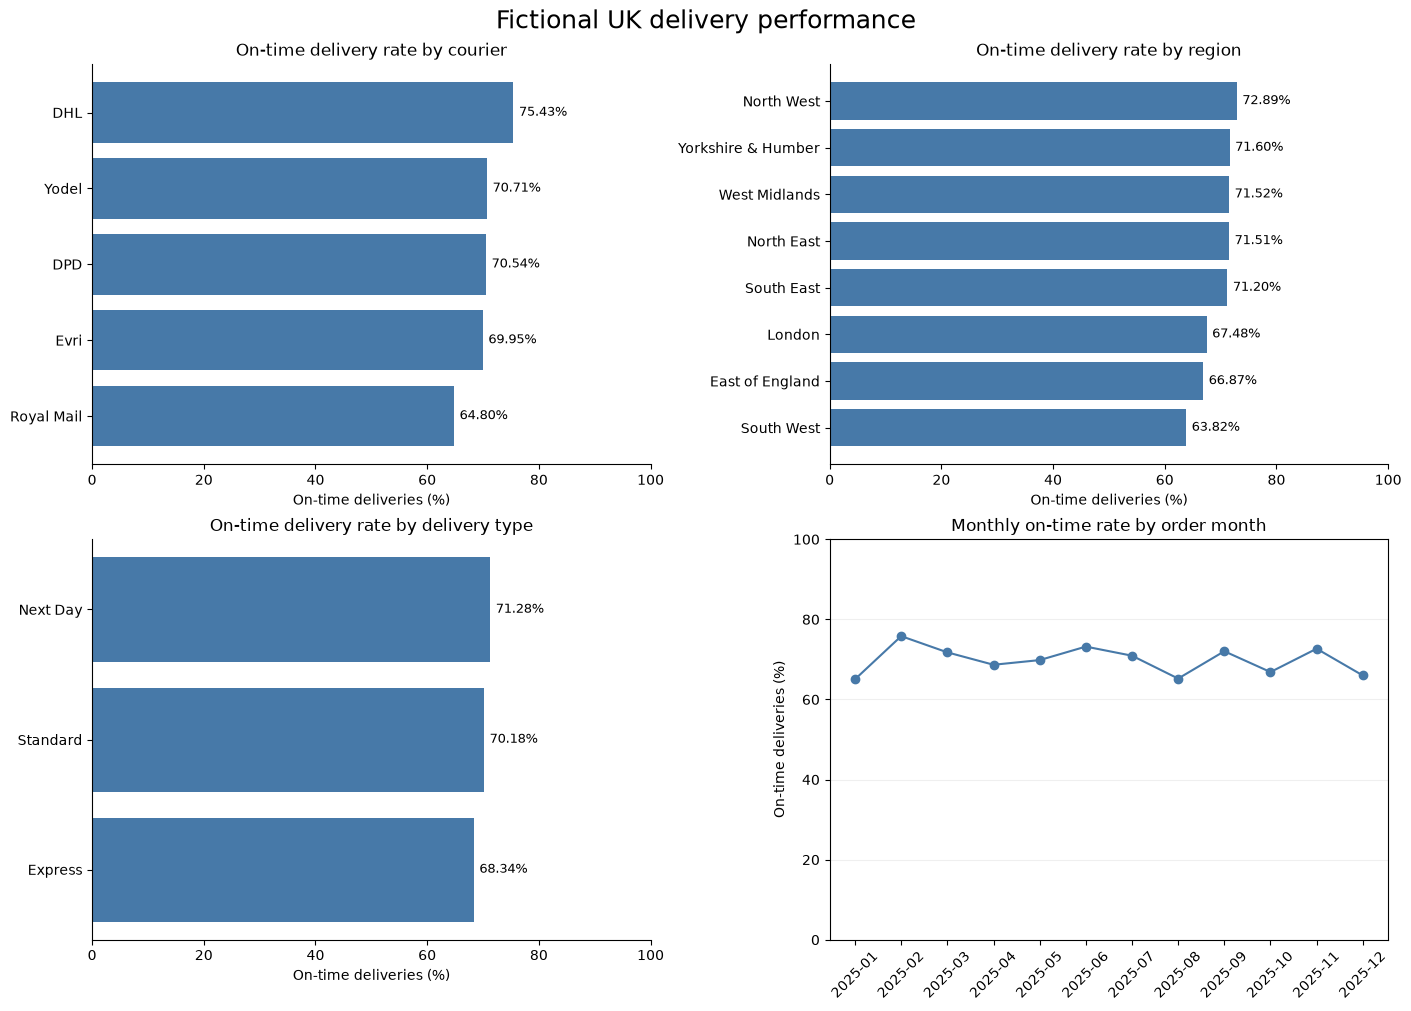

         deliveries  on_time_rate
month                            
2025-01         186        0.6505
2025-02         153        0.7582
2025-03         170        0.7176
2025-04         150        0.6867
2025-05         179        0.6983
2025-06         153        0.7320
2025-07         172        0.7093
2025-08         184        0.6522
2025-09         186        0.7204
2025-10         184        0.6685
2025-11         183        0.7268
2025-12         100        0.6600


In [8]:
monthly = clean.groupby('month').agg(
    deliveries=('delivery_id', 'size'),
    on_time_rate=('is_on_time', 'mean')
).sort_index()

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, title, summary in [
    (axes[0, 0], 'On-time delivery rate by courier', courier_summary),
    (axes[0, 1], 'On-time delivery rate by region', region_summary),
    (axes[1, 0], 'On-time delivery rate by delivery type', type_summary)
]:
    values = summary['on_time_rate'].sort_values() * 100
    ax.barh(values.index, values.values, color='#4779a8')
    ax.set_xlim(0, 100)
    ax.set_xlabel('On-time deliveries (%)')
    ax.set_title(title)
    for index, value in enumerate(values):
        ax.text(value + 1, index, f'{value:.2f}%', va='center', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

ax = axes[1, 1]
ax.plot(monthly.index, monthly['on_time_rate'] * 100, marker='o', color='#4779a8')
ax.set_ylim(0, 100)
ax.set_ylabel('On-time deliveries (%)')
ax.set_title('Monthly on-time rate by order month')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.2)
fig.suptitle('Fictional UK delivery performance', fontsize=18)
fig.savefig(BASE_DIR / 'python_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(monthly.round(4).to_string())

## Export and reconcile with the supplied reference

Export only the same 18 columns used in the supplied cleaned CSV. The temporary boolean helper is excluded. Then compare every identifier, field and derived metric with the reference, using a small numeric tolerance only for floating-point representation. A mismatch stops execution; the reference is not used to fix or force the results.


In [9]:
export_columns = list(raw.columns) + ['delivery_time_days', 'days_late', 'on_time_status', 'month']
export_data = clean[export_columns].copy()
export_data.to_csv(OUTPUT_FILE, index=False, date_format='%Y-%m-%d')
actual = pd.read_csv(OUTPUT_FILE).sort_values('delivery_id').reset_index(drop=True)
reference = pd.read_csv(REFERENCE_FILE).sort_values('delivery_id').reset_index(drop=True)
assert list(actual.columns) == list(reference.columns), 'Column mismatch'
pd.testing.assert_frame_equal(actual, reference, check_dtype=False, check_exact=False,
                              rtol=1e-10, atol=1e-10)
print(f'Exported {len(actual):,} rows to {OUTPUT_FILE.name}')
print('All 18 columns match the supplied reference across 2,000 deliveries.')
print('All date-derived metrics and headline dashboard KPIs reconcile.')

Exported 2,000 rows to delivery_logistics_cleaned.csv
All 18 columns match the supplied reference across 2,000 deliveries.
All date-derived metrics and headline dashboard KPIs reconcile.


## Interpretation and interview discussion

The dataset has a 69.85% on-time rate and 30.15% late rate. DHL has the highest on-time percentage among the fictional courier labels, and North West has the highest regional percentage. These observations suggest where to investigate differences; they do not show why differences occur.

Be ready to explain why the median was used for missing distances, why missing ratings were retained, how the on-time denominator is defined, how a window of calendar days differs from business days, and why group percentages should be considered alongside delivery counts.

The Tableau dashboard remains a separate supplied artefact. Notebook execution and CSV reconciliation do not validate Tableau refresh, filters or interactions. To refresh Tableau, point its data source to `delivery_logistics_cleaned.csv` and verify the unfiltered KPIs.
